In [ ]:
import os
import time
import numpy as np
import pandas as pd

import numpy as np
from tqdm.notebook import tqdm

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.metrics import confusion_matrix, f1_score, classification_report, accuracy_score
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
import joblib

import mne

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from keras.layers import Dense
from keras.regularizers import l2
from keras import backend as K
from tensorflow.keras.layers import (
    Conv1D, MaxPooling1D, GlobalMaxPooling1D, Dropout,
    Flatten, Dense, Reshape, LSTM, SimpleRNN, GRU, Bidirectional, Activation
)

from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Dropout, Flatten,
    BatchNormalization, DepthwiseConv2D, AveragePooling2D, SeparableConv2D
)

from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models, Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import load_model
#from wandb.integration.keras import WandbCallback
import warnings
warnings.filterwarnings('ignore')

In [ ]:
dataset_path = "Cricket/Dataset" # Adjust this path to your folder
output_path = "Cricket/Results" # Adjust this path for results

excel_dfs = {}

# Ensure the output directory exists in Drive
os.makedirs(dataset_path, exist_ok=True)

# Display the keys of the loaded DataFrames
print("\nLoaded Excel files:", excel_dfs.keys())

Successfully loaded 'Cricket - Copy.xlsx' with shape (2979, 2)
Successfully loaded 'Cricket Sentiment Analysis.xlsx' with shape (149, 2)
Successfully loaded 'cricket_comments_balanced.xlsx' with shape (17652, 2)
Successfully loaded 'Facebook Cricket Comments.xlsx' with shape (5000, 2)

Loaded Excel files: dict_keys(['Cricket - Copy', 'Cricket Sentiment Analysis', 'cricket_comments_balanced', 'Facebook Cricket Comments'])


In [ ]:
print("Combining all dataframes from 'excel_dfs'...")
combined_df = pd.concat(excel_dfs.values(), ignore_index=True)
df = combined_df

display(df.head())

Combining all dataframes from 'excel_dfs'...
Combined DataFrame created successfully!
First 5 rows of the combined dataset:


,Comments,Sentiment
0,জয় বাংলা কাপ! তাও আবার স্বাধীনতার মাস মার্চে। ...,positive
1,জয় বাংলা কাপ! তাও আবার স্বাধীনতার মাস মার্চে। ...,positive
2,বাংলাদেশের পরে ভারতের সাপর্ট ই করি ?,positive
3,সৌম্যকে বাদ দেওয়া হোক,negative
4,"প্রথমটি হচ্ছে, কোচ অত:পর সাকিব,সাকিব আর সাকিবর...",positive


Shape of the combined DataFrame: (25780, 2)


In [ ]:
import numpy as np
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['encoded_label'] = le.fit_transform(df[LABEL_COLUMN])

Label Mapping:
  negative  →  0
  neutral  →  1
  positive  →  2

Total samples : 25780
Num classes   : 3


In [ ]:
def preprocess_bangla(text):
    if not isinstance(text, str):
        return ''
    text = re.sub(r'http\S+|www\S+', '', text)          # remove URLs
    text = re.sub(r'<.*?>', '', text)                    # remove HTML tags
    text = re.sub(r'[a-zA-Z]', '', text)                 # remove English letters
    text = re.sub(r'[0-9০-৯]', '', text)                # remove digits
    text = re.sub(r'[^\u0980-\u09FF\s]', '', text)      # keep only Bangla Unicode
    text = re.sub(r'\s+', ' ', text).strip()             # normalize whitespace
    return text

df['cleaned_text'] = df[TEXT_COLUMN].apply(preprocess_bangla)
df = df[df['cleaned_text'].str.strip() != ''].reset_index(drop=True)

# Tokenize
df['tokens'] = df['cleaned_text'].apply(lambda x: x.split())
corpus = df['tokens'].tolist()

print(f'Samples after cleaning: {len(df)}')
print('\nSample before/after:')
for i in range(3):
    print(f'  Original : {df[TEXT_COLUMN].iloc[i]}')
    print(f'  Cleaned  : {df["cleaned_text"].iloc[i]}')
    print(f'  Tokens   : {df["tokens"].iloc[i]}')
    print()

Samples after cleaning: 25779

Sample before/after:
  Original : জয় বাংলা কাপ! তাও আবার স্বাধীনতার মাস মার্চে। যার মাথা থেকে এমন চমৎকার আইডিয়া এসেছে তালে স্যালুট
  Cleaned  : জয় বাংলা কাপ তাও আবার স্বাধীনতার মাস মার্চে যার মাথা থেকে এমন চমৎকার আইডিয়া এসেছে তালে স্যালুট
  Tokens   : ['জয়', 'বাংলা', 'কাপ', 'তাও', 'আবার', 'স্বাধীনতার', 'মাস', 'মার্চে', 'যার', 'মাথা', 'থেকে', 'এমন', 'চমৎকার', 'আইডিয়া', 'এসেছে', 'তালে', 'স্যালুট']

  Original : জয় বাংলা কাপ! তাও আবার স্বাধীনতার মাস মার্চে। যার মাথা থেকে এমন চমৎকার আইডিয়া এসেছে তালে স্যালুট
  Cleaned  : জয় বাংলা কাপ তাও আবার স্বাধীনতার মাস মার্চে যার মাথা থেকে এমন চমৎকার আইডিয়া এসেছে তালে স্যালুট
  Tokens   : ['জয়', 'বাংলা', 'কাপ', 'তাও', 'আবার', 'স্বাধীনতার', 'মাস', 'মার্চে', 'যার', 'মাথা', 'থেকে', 'এমন', 'চমৎকার', 'আইডিয়া', 'এসেছে', 'তালে', 'স্যালুট']

  Original : বাংলাদেশের পরে ভারতের সাপর্ট ই করি ?
  Cleaned  : বাংলাদেশের পরে ভারতের সাপর্ট ই করি
  Tokens   : ['বাংলাদেশের', 'পরে', 'ভারতের', 'সাপর্ট', 'ই', 'করি']



In [ ]:
df = df.dropna(subset=[TEXT_COLUMN, LABEL_COLUMN]).copy()
df[TEXT_COLUMN] = df[TEXT_COLUMN].astype(str).str.strip()
df = df[df[TEXT_COLUMN] != ''].reset_index(drop=True)

# Tokenize by whitespace.
# If you already have a token-list column, replace this with that column.
df['tokens'] = df[TEXT_COLUMN].apply(lambda x: x.split())

print(df['tokens'].head())

0    [জয়, বাংলা, কাপ!, তাও, আবার, স্বাধীনতার, মাস, ...
1    [জয়, বাংলা, কাপ!, তাও, আবার, স্বাধীনতার, মাস, ...
2         [বাংলাদেশের, পরে, ভারতের, সাপর্ট, ই, করি, ?]
3                           [সৌম্যকে, বাদ, দেওয়া, হোক]
4    [প্রথমটি, হচ্ছে,, কোচ, অত:পর, সাকিব,সাকিব, আর,...
Name: tokens, dtype: object


In [ ]:
from gensim.models import FastText

# Define FastText hyperparameters
EMBEDDING_DIM = 100  # Dimension of word embeddings
WINDOW = 5           # Context window size
MIN_COUNT = 5        # Ignores all words with total frequency lower than this
WORKERS = 4          # Number of CPU cores to use for training
SG = 1               # Training algorithm: 1 for skip-gram, 0 for CBOW
NEGATIVE = 5         # Number of "negative" samples
EPOCHS = 10          # Number of iterations (epochs) over the corpus
MIN_N = 3            # Minimum n-gram size
MAX_N = 6            # Maximum n-gram size
SEED = 42            # Random seed for reproducibility

sentences = df['tokens'].tolist()

fasttext_model = FastText(
    sentences=sentences,
    vector_size=EMBEDDING_DIM,
    window=WINDOW,
    min_count=MIN_COUNT,
    workers=WORKERS,
    sg=SG,
    negative=NEGATIVE,
    epochs=EPOCHS,
    min_n=MIN_N,
    max_n=MAX_N,
    seed=SEED
)

print('Vocabulary size:', len(fasttext_model.wv))
print('Embedding dimension:', fasttext_model.vector_size)

Vocabulary size: 4812
Embedding dimension: 100


In [ ]:
sample_words = list(fasttext_model.wv.index_to_key[:10])

for word in sample_words:
    print(f'{word}: {fasttext_model.wv[word][:10]} ...')

এর: [-0.0625113   0.48331875  0.0435339   0.3640908  -0.35871202  0.06591436
 -0.17346099 -0.4039247   0.23305649 -0.6203764 ] ...
এবং: [ 0.26337668  0.50533044 -0.42684105  0.76475984 -0.24981001  0.11581923
 -0.12471366 -0.6596985   0.01994193 -0.57394224] ...
আজ: [ 0.28633204  0.64828295 -0.28622922  0.558239   -0.32846886 -0.4703597
 -0.2268053   0.18213564 -0.05080768 -0.5141451 ] ...
ম্যাচে: [ 0.08660795  0.74616444 -0.55981916  0.8065652   0.78838134 -0.125797
 -0.21613407  0.33929223 -0.34520796 -0.47961116] ...
মধ্যে: [-0.14393555  0.38857573 -0.59633267  0.8246208  -0.12235835  0.49889505
 -0.44063762 -0.3511573  -0.04157522 -0.0643551 ] ...
নম্বর: [ 0.03169957  0.6994244  -0.37381035  1.1855923  -0.32239613  0.3483463
 -0.21281762 -0.6169179  -0.493343   -0.93408   ] ...
হবে: [ 0.1278094   0.458242   -0.3468092   0.82730424 -0.57962126  0.31605482
 -0.10087077 -0.42186117 -0.02656643 -0.84577096] ...
না: [-0.19190922  0.34213498  0.18821897 -0.06953344 -0.13261056 -0.2344976

In [ ]:
def create_fasttext_sequences(tokenized_texts, model, max_len, embedding_dim):
    X = np.zeros(
        (len(tokenized_texts), max_len, embedding_dim),
        dtype=np.float32
    )

    for i, tokens in enumerate(tokenized_texts):
        for j, word in enumerate(tokens[:max_len]):
            if word in model.wv:
                X[i, j] = model.wv[word]

    return X

X_w2v = create_fasttext_sequences(
    df['tokens'].tolist(),
    fasttext_model,
    MAX_LEN,
    EMBEDDING_DIM
)

print('X_w2v shape:', X_w2v.shape)

X_w2v shape: (25779, 52, 100)


In [ ]:
y = df['encoded_label'].to_numpy()

print('Label shape:', y.shape)
print('Unique labels:', np.unique(y))

Label shape: (25779,)
Unique labels: [0 1 2]

Label distribution:
0    9088
1    7580
2    9111
Name: count, dtype: int64


In [ ]:
# Extract sentence vectors by averaging token vectors
def get_fasttext_vector(tokens, model, dim=100):
    vectors = [model.wv[w] for w in tokens if w in model.wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(dim)

X = np.array([get_fasttext_vector(tokens, fasttext_model) for tokens in corpus])
y = df['encoded_label'].values

print(f'Feature matrix shape : {X.shape}')
print(f'Labels shape         : {y.shape}')

Feature matrix shape : (25779, 100)
Labels shape         : (25779,)


In [ ]:
OUTPUT_DIR = output_path # Define OUTPUT_DIR using the globally available output_path
X_PATH = os.path.join(OUTPUT_DIR, 'X_fasttext_sequence.npy')
Y_PATH = os.path.join(OUTPUT_DIR, 'y_labels.npy')
MODEL_PATH = os.path.join(OUTPUT_DIR, 'bangla_fasttext.model')

np.save(X_PATH, X)
np.save(Y_PATH, y)
fasttext_model.save(MODEL_PATH)

print('Saved:')
print(X_PATH)
print(Y_PATH)
print(MODEL_PATH)

Saved:
C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\X_fasttext_sequence.npy
C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\y_labels.npy
C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\bangla_fasttext.model


In [ ]:
X_loaded = np.load(X_PATH)
y_loaded = np.load(Y_PATH)

print('Loaded X shape:', X_loaded.shape)
print('Loaded y shape:', y_loaded.shape)
print('X dtype:', X_loaded.dtype)
print('First sample shape:', X_loaded[0].shape)

Loaded X shape: (25779, 100)
Loaded y shape: (25779,)
X dtype: float32
First sample shape: (100,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)
print(f'✅ Split Complete:')
print(f'  X_train: {X_train.shape}, y_train: {y_train.shape}')
print(f'  X_test : {X_test.shape},  y_test : {y_test.shape}')
print(f'  X_train: {X_val.shape}, y_train: {y_val.shape}')

✅ Split Complete:
  X_train: (18045, 100), y_train: (18045,)
  X_test : (3867, 100),  y_test : (3867,)
  X_train: (3867, 100), y_train: (3867,)


**CNN**

In [ ]:
X_train_1d = X_train.reshape(-1, X_train.shape[1], 1)
X_test_1d = X_test.reshape(-1, X_test.shape[1], 1)
X_val_1d = X_val.reshape(-1, X_val.shape[1], 1)

print(f'Reshaped X_train_1d: {X_train_1d.shape}')
print(f'Reshaped X_test_1d: {X_test_1d.shape}')
print(f'Reshaped X_val_1d: {X_val_1d.shape}')

Reshaped X_train_1d: (18045, 100, 1)
Reshaped X_test_1d: (3867, 100, 1)
Reshaped X_val_1d: (3867, 100, 1)


In [ ]:
from keras.models import Sequential
from keras.layers import Conv1D, MaxPooling1D, BatchNormalization, Dropout, Flatten, Dense

model1d = Sequential()

# First Conv1D block
model1d.add(Conv1D(filters=64, kernel_size=5, activation='elu', input_shape=(X_train.shape[1], 1)))
model1d.add(BatchNormalization())
model1d.add(MaxPooling1D(pool_size=2))
model1d.add(Dropout(0.3))

# Second Conv1D block
model1d.add(Conv1D(filters=128, kernel_size=3, activation='elu'))
model1d.add(BatchNormalization())
model1d.add(MaxPooling1D(pool_size=2))
model1d.add(Dropout(0.4))

# Third Conv1D block
model1d.add(Conv1D(filters=256, kernel_size=3, activation='elu'))
model1d.add(BatchNormalization())
model1d.add(MaxPooling1D(pool_size=2))
model1d.add(Dropout(0.4))

model1d.add(Flatten())

# Dense layers
model1d.add(Dense(128, activation='elu'))
model1d.add(Dropout(0.3))

# Output layer for multi-class classification (5 classes)
# `le` (LabelEncoder) was defined in a previous cell (s3-code)
model1d.add(Dense(len(le.classes_), activation='softmax'))

In [ ]:
model1d.compile(optimizer='Adagrad', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model1d.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 96, 64)              │             384 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 96, 64)              │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 48, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 48, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 46, 128)             │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 46, 128)             │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_1 (MaxPooling1D)       │ (None, 23, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 23, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                    │ (None, 21, 256)             │          98,560 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 21, 256)             │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_2 (MaxPooling1D)       │ (None, 10, 256)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 10, 256)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2560)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         327,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 453,635 (1.73 MB)

 Trainable params: 452,739 (1.73 MB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
history_1d = model1d.fit(
    X_train_1d,
    y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8195 - loss: 0.3845 - val_accuracy: 0.8373 - val_loss: 0.3495
Epoch 2/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8197 - loss: 0.3816 - val_accuracy: 0.8389 - val_loss: 0.3449
Epoch 3/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8182 - loss: 0.3789 - val_accuracy: 0.8384 - val_loss: 0.3430
Epoch 4/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8208 - loss: 0.3746 - val_accuracy: 0.8404 - val_loss: 0.3408
Epoch 5/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8239 - loss: 0.3742 - val_accuracy: 0.8410 - val_loss: 0.3415
Epoch 6/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8241 - loss: 0.3704 - val_accuracy: 0.8448 - val_loss: 0.3384
Epoch 7/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8243 - loss: 0.3678 - val_accuracy: 0.8404 - val_loss: 0.3398
Epoch 8/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8271 - loss: 0.3690 - val_accu

In [ ]:
# Predict probabilities on the test set for the best CNN model
y_pred_probs_test_best_cnn = model1d.predict(X_test_1d)
# Convert probabilities to class labels
y_predict_best_cnn_test = np.argmax(y_pred_probs_test_best_cnn, axis=1)

# Compute confusion matrix for the best CNN model on test data
cm_best_cnn_test = confusion_matrix(y_test, y_predict_best_cnn_test)
print("Confusion Matrix for Test Data (Best CNN Model):")
print(cm_best_cnn_test)

121/121 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Confusion Matrix for Test Data (Best CNN Model):
[[1012    8  344]
 [  27 1094   16]
 [ 283   11 1072]]


In [ ]:
from tensorflow.keras.losses import SparseCategoricalCrossentropy



# Calculate loss manually
scce_loss_fn = SparseCategoricalCrossentropy(from_logits=False)
loss = scce_loss_fn(y_test, y_pred_probs_test_best_cnn).numpy()

# Calculate accuracy manually
accuracy = accuracy_score(y_test, y_predict_best_cnn_test)

macro_f1 = f1_score(y_test, y_predict_best_cnn_test, average='macro')

output_text = (
    f'Test Loss of Best CNN Model: {loss:.4f}\n' +
    f'Test Accuracy of Best CNN Model: {accuracy:.4f}\n' +
    f'Test Macro F1 Score of Best CNN Model: {macro_f1:.4f}'
)

print(output_text)

# Save the output to a text file
file_dir = base_save_dir # Use base_save_dir directly for consistency
output_report_path = os.path.join(file_dir, 'cnn_test_evaluation_metrics_w.txt')
with open(output_report_path, 'w') as f:
    f.write(output_text)
print(f"CNN test evaluation metrics saved to: {output_report_path}")

Test Loss of Best CNN Model: 0.4498
Test Accuracy of Best CNN Model: 0.8218
Test Macro F1 Score of Best CNN Model: 0.8307
CNN test evaluation metrics saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\cnn_test_evaluation_metrics_w.txt


Accuracy plot saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\cnn_accuracy_plot_w.png


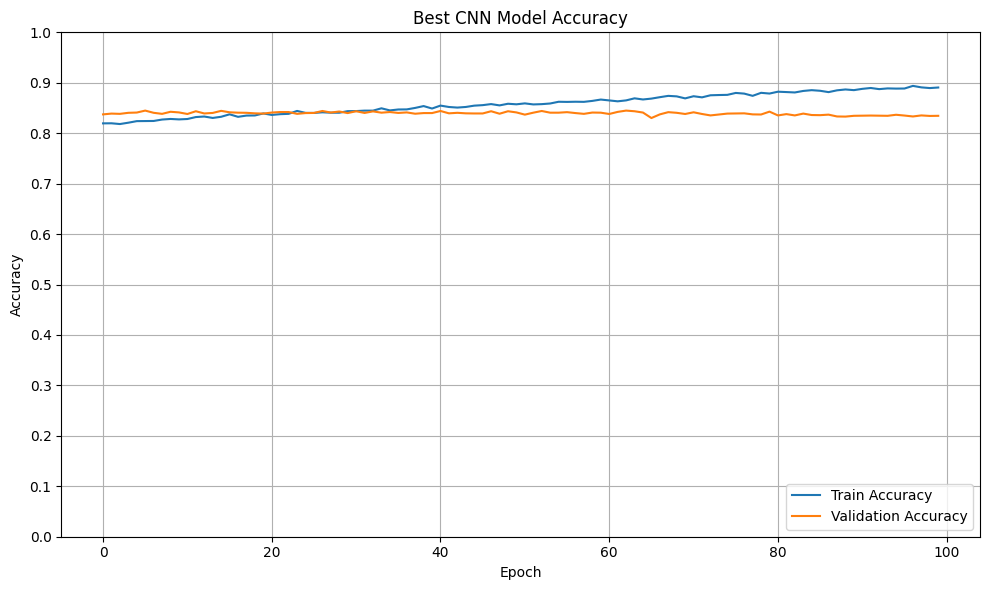

In [ ]:
# Use base_save_dir directly for consistency
file_dir = base_save_dir

# Plot training & validation accuracy values
plt.figure(figsize=(10, 6))
plt.plot(history_1d.history['accuracy'], label='Train Accuracy')
plt.plot(history_1d.history['val_accuracy'], label='Validation Accuracy')
plt.title('Best CNN Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([i / 10 for i in range(11)])
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()

# Save the plot to Google Drive
accuracy_plot_path = os.path.join(file_dir, 'cnn_accuracy_plot_w.png') # Keeping original name for now
plt.savefig(accuracy_plot_path)
print(f"Accuracy plot saved to: {accuracy_plot_path}")
plt.show()

Loss plot saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\cnn_loss_plot_w.png


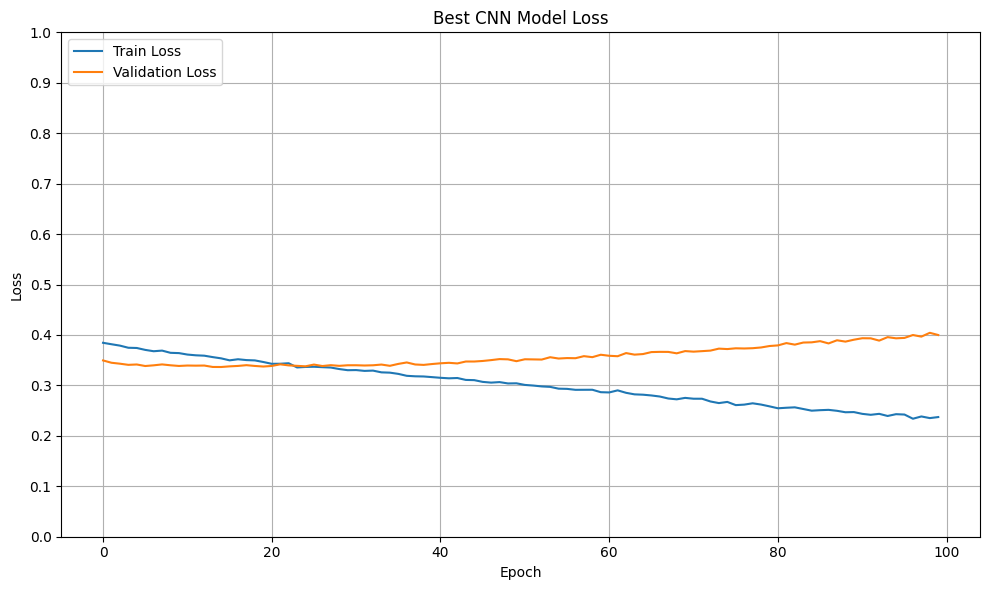

In [ ]:
# Use base_save_dir directly for consistency
file_dir = base_save_dir

# Plot training & validation loss values
plt.figure(figsize=(10, 6))
plt.plot(history_1d.history['loss'], label='Train Loss')
plt.plot(history_1d.history['val_loss'], label='Validation Loss')
plt.title('Best CNN Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.yticks([i / 10 for i in range(11)])
plt.legend(loc='upper left')
plt.grid(True)
plt.tight_layout()

# Save the plot to Google Drive
loss_plot_path = os.path.join(file_dir, 'cnn_loss_plot_w.png')
plt.savefig(loss_plot_path)
print(f"Loss plot saved to: {loss_plot_path}")
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np


y_pred_probs_train_cnn_model1d_eval = best_cnn_model.predict(X_train_1d)
y_predict_cnn_model1d_eval_train = np.argmax(y_pred_probs_train_cnn_model1d_eval, axis=1)

# Compute confusion matrix
cm_cnn_model1d_eval_train = confusion_matrix(y_train, y_predict_cnn_model1d_eval_train)
print("Confusion Matrix for Train Data (CNN Model1D Evaluation - now using Best CNN Model):")
print(cm_cnn_model1d_eval_train)

564/564 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Confusion Matrix for Train Data (CNN Model1D Evaluation - now using Best CNN Model):
[[5730    7  624]
 [   5 5299    2]
 [ 469    5 5904]]


Training Confusion Matrix plot saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\cnn_model1d_eval_train_confusion_matrix_w.png


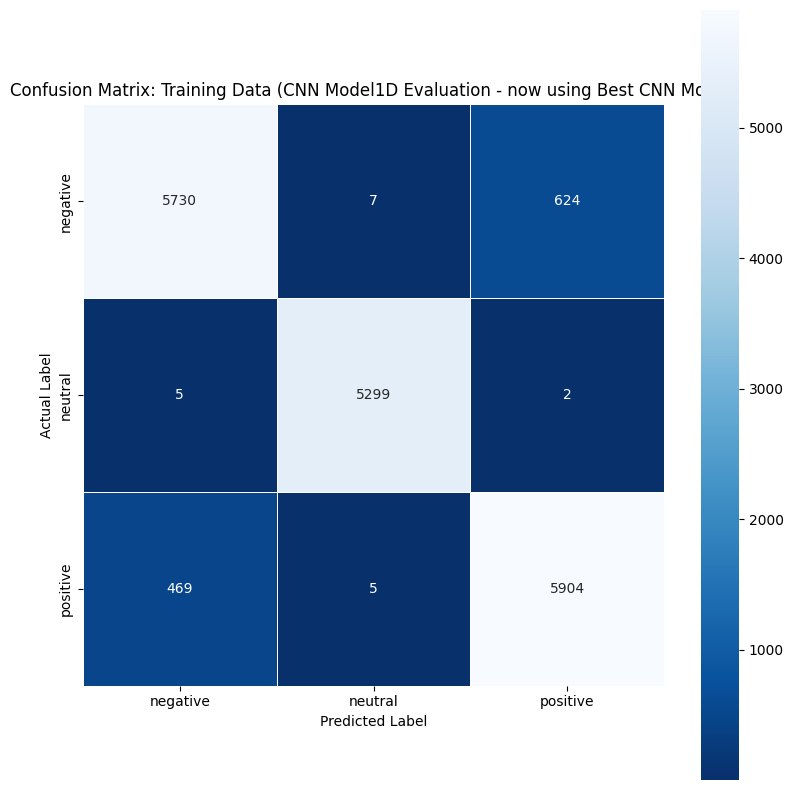

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Use base_save_dir directly for consistency
file_dir = base_save_dir

plt.figure(figsize = (8,8))
sns.heatmap(cm_cnn_model1d_eval_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix: Training Data (CNN Model1D Evaluation - now using Best CNN Model)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Save the plot to Google Drive
train_cm_plot_path_cnn_model1d_eval = os.path.join(file_dir, 'cnn_model1d_eval_train_confusion_matrix_w.png')
plt.savefig(train_cm_plot_path_cnn_model1d_eval)
print(f"Training Confusion Matrix plot saved to: {train_cm_plot_path_cnn_model1d_eval}")
plt.show()

In [ ]:
report_cnn_model1d_eval_train = classification_report(y_train, y_predict_cnn_model1d_eval_train, target_names=le.classes_)
print("CNN Model1D Evaluation Train Report (now using Best CNN Model):\n", report_cnn_model1d_eval_train)

CNN Model1D Evaluation Train Report (now using Best CNN Model):
               precision    recall  f1-score   support

    negative       0.92      0.90      0.91      6361
     neutral       1.00      1.00      1.00      5306
    positive       0.90      0.93      0.91      6378

    accuracy                           0.94     18045
   macro avg       0.94      0.94      0.94     18045
weighted avg       0.94      0.94      0.94     18045

Training Classification Report saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\cnn_model1d_eval_train_classification_report_w.txt


In [ ]:
y_pred_probs_test_cnn_model1d_eval = best_cnn_model.predict(X_test_1d)
y_predict_cnn_model1d_eval_test = np.argmax(y_pred_probs_test_cnn_model1d_eval, axis=1)

# Compute confusion matrix
cm_cnn_model1d_eval_test = confusion_matrix(y_test, y_predict_cnn_model1d_eval_test)
print("Confusion Matrix for Test Data (CNN Model1D Evaluation - now using Best CNN Model):")
print(cm_cnn_model1d_eval_test)

121/121 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Confusion Matrix for Test Data (CNN Model1D Evaluation - now using Best CNN Model):
[[1012    8  344]
 [  27 1094   16]
 [ 283   11 1072]]


Test Confusion Matrix plot saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\cnn_model1d_eval_test_confusion_matrix_w.png


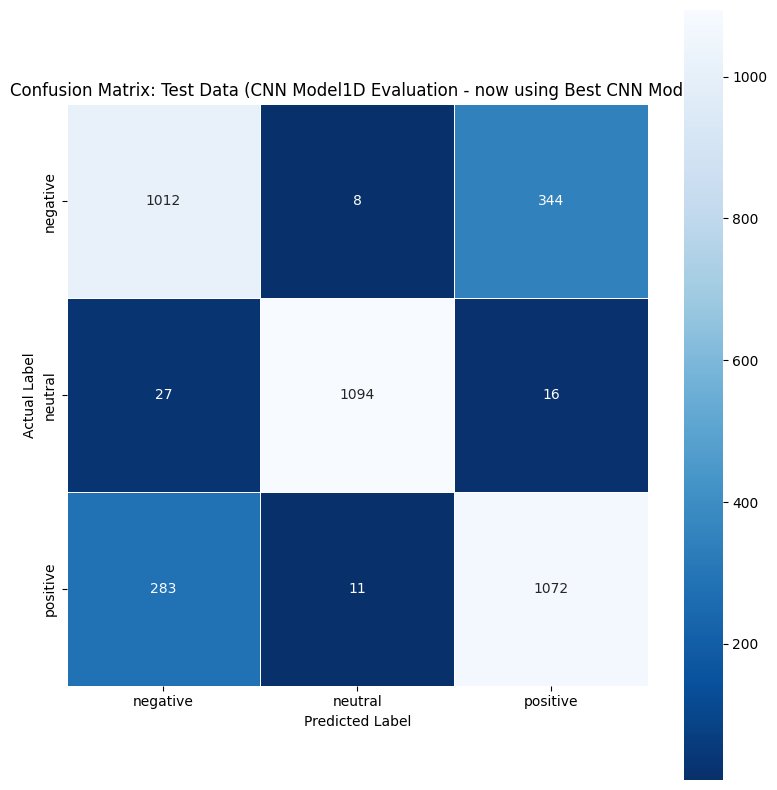

In [ ]:
file_dir = base_save_dir

plt.figure(figsize = (8,8))
sns.heatmap(cm_cnn_model1d_eval_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix: Test Data (CNN Model1D Evaluation - now using Best CNN Model)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Save the plot to Google Drive
test_cm_plot_path_cnn_model1d_eval = os.path.join(file_dir, 'cnn_model1d_eval_test_confusion_matrix_w.png')
plt.savefig(test_cm_plot_path_cnn_model1d_eval)
print(f"Test Confusion Matrix plot saved to: {test_cm_plot_path_cnn_model1d_eval}")
plt.show()

In [ ]:
report_cnn_model1d_eval_test = classification_report(y_test, y_predict_cnn_model1d_eval_test, target_names=le.classes_)
print("CNN Model1D Evaluation Test Report (now using Best CNN Model):\n", report_cnn_model1d_eval_test)

CNN Model1D Evaluation Test Report (now using Best CNN Model):
               precision    recall  f1-score   support

    negative       0.77      0.74      0.75      1364
     neutral       0.98      0.96      0.97      1137
    positive       0.75      0.78      0.77      1366

    accuracy                           0.82      3867
   macro avg       0.83      0.83      0.83      3867
weighted avg       0.82      0.82      0.82      3867

Test Classification Report saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\cnn_model1d_eval_test_classification_report_w.txt


CNN Model1D Evaluation ROC curve plot saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\cnn_model1d_eval_roc_curve_w.png


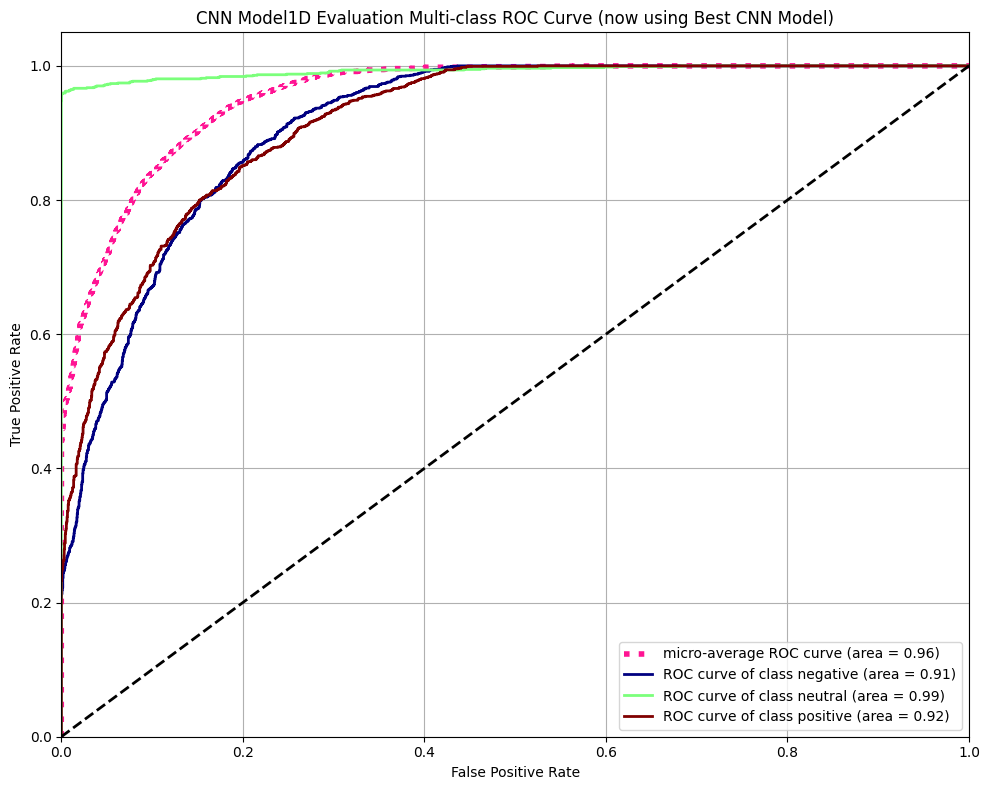

In [ ]:
file_dir = base_save_dir

# Get the number of classes
n_classes = len(le.classes_)

# Convert y_test to one-hot encoding
y_test_one_hot = to_categorical(y_test, num_classes=n_classes)

# Compute ROC curve and ROC area for each class
fpr_cnn_model1d_eval = dict()
tpr_cnn_model1d_eval = dict()
roc_auc_cnn_model1d_eval = dict()
for i in range(n_classes):
    fpr_cnn_model1d_eval[i], tpr_cnn_model1d_eval[i], _ = roc_curve(y_test_one_hot[:, i], y_pred_probs_test_cnn_model1d_eval[:, i])
    roc_auc_cnn_model1d_eval[i] = auc(fpr_cnn_model1d_eval[i], tpr_cnn_model1d_eval[i])

# Compute micro-average ROC curve and ROC area
fpr_micro_cnn_model1d_eval, tpr_micro_cnn_model1d_eval, _ = roc_curve(y_test_one_hot.ravel(), y_pred_probs_test_cnn_model1d_eval.ravel())
roc_auc_micro_cnn_model1d_eval = auc(fpr_micro_cnn_model1d_eval, tpr_micro_cnn_model1d_eval)

# Plot all ROC curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_micro_cnn_model1d_eval, tpr_micro_cnn_model1d_eval,
         label='micro-average ROC curve (area = {0:0.2f})'
               ''.format(roc_auc_micro_cnn_model1d_eval),
         color='deeppink', linestyle=':', linewidth=4)

colors = plt.cm.get_cmap('jet', n_classes)
for i, color in zip(range(n_classes), colors(np.linspace(0, 1, n_classes))):
    plt.plot(fpr_cnn_model1d_eval[i], tpr_cnn_model1d_eval[i], color=color, lw=2,
             label='ROC curve of class {0} (area = {1:0.2f})'
                   ''.format(le.classes_[i], roc_auc_cnn_model1d_eval[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('CNN Model1D Evaluation Multi-class ROC Curve (now using Best CNN Model)')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()

# Save the plot
roc_plot_path_cnn_model1d_eval = os.path.join(file_dir, 'cnn_model1d_eval_roc_curve_w.png')
plt.savefig(roc_plot_path_cnn_model1d_eval)
print(f"CNN Model1D Evaluation ROC curve plot saved to: {roc_plot_path_cnn_model1d_eval}")
plt.show()

**LSTM**

In [ ]:
X_train_lstm = X_train.reshape(X_train.shape[0], 1, X_train.shape[1])
X_test_lstm = X_test.reshape(X_test.shape[0], 1, X_test.shape[1])

print(f'Reshaped X_train_lstm: {X_train_lstm.shape}')
print(f'Reshaped X_test_lstm: {X_test_lstm.shape}')

Reshaped X_train_lstm: (18045, 1, 100)
Reshaped X_test_lstm: (3867, 1, 100)


In [ ]:
from keras.models import Sequential
from keras.layers import LSTM, BatchNormalization, Dropout, Dense

model_lstm = Sequential()

model_lstm.add(LSTM(units=256, input_shape=(1, X_train.shape[1])))
model_lstm.add(BatchNormalization())
model_lstm.add(Dropout(0.5))

model_lstm.add(Dense(100, activation='elu'))
model_lstm.add(BatchNormalization())
model_lstm.add(Dropout(0.3))

model_lstm.add(Dense(50, activation = 'elu'))
model_lstm.add(Dropout(0.3))

# Output layer for multi-class classification (5 classes)
# `le` (LabelEncoder) was defined in a previous cell (s3-code)
model_lstm.add(Dense(len(le.classes_), activation='softmax'))

In [ ]:
model_lstm.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_lstm.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 256)                 │         365,568 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 100)                 │          25,700 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 100)                 │             400 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 50)                  │           5,050 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 50)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 3)                   │             153 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 397,895 (1.52 MB)

 Trainable params: 397,183 (1.52 MB)

 Non-trainable params: 712 (2.78 KB)

In [ ]:
X_val_lstm = X_val.reshape(X_val.shape[0], 1, X_val.shape[1])
history_lstm = model_lstm.fit(X_train_lstm, y_train, epochs=100, batch_size=32, validation_data=(X_val_lstm, y_val))

Epoch 1/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8273 - loss: 0.3788 - val_accuracy: 0.8345 - val_loss: 0.3534
Epoch 2/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8293 - loss: 0.3728 - val_accuracy: 0.8392 - val_loss: 0.3474
Epoch 3/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8287 - loss: 0.3696 - val_accuracy: 0.8384 - val_loss: 0.3437
Epoch 4/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8301 - loss: 0.3652 - val_accuracy: 0.8397 - val_loss: 0.3443
Epoch 5/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8306 - loss: 0.3645 - val_accuracy: 0.8412 - val_loss: 0.3489
Epoch 6/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8352 - loss: 0.3585 - val_accuracy: 0.8379 - val_loss: 0.3458
Epoch 7/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8367 - loss: 0.3596 - val_accuracy: 0.8410 - val_loss: 0.3424
Epoch 8/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8342 - loss: 0.3550 - val_accu

In [ ]:
y_pred_probs_test_best_lstm = model_lstm.predict(X_test_lstm, verbose=0)
y_predict_best_lstm_test = np.argmax(y_pred_probs_test_best_lstm, axis=1)


loss_lstm, accuracy_lstm = best_lstm_model.evaluate(X_test_lstm, y_test, verbose=0)
macro_f1_lstm = f1_score(y_test, y_predict_best_lstm_test, average='macro')

output_text = (
    f'Test Loss of Best LSTM Model: {loss_lstm:.4f}\n' +
    f'Test Accuracy of Best LSTM Model: {accuracy_lstm:.4f}\n' +
    f'Test Macro F1 Score of Best LSTM Model: {macro_f1_lstm:.4f}'
)

print(output_text)

print(f"LSTM test evaluation metrics saved to: {output_report_path}")

Test Loss of Best LSTM Model: 0.6422
Test Accuracy of Best LSTM Model: 0.8192
Test Macro F1 Score of Best LSTM Model: 0.8281
LSTM test evaluation metrics saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\lstm_test_evaluation_metrics_w.txt


In [ ]:
# Evaluate the best LSTM model on the test data (re-evaluation)
loss_re_eval_lstm, accuracy_re_eval_lstm = best_lstm_model.evaluate(X_test_lstm, y_test, verbose=0)
print(f'Test Loss (re-evaluated Best LSTM Model): {loss_re_eval_lstm:.4f}')
print(f'Test Accuracy (re-evaluated Best LSTM Model): {accuracy_re_eval_lstm:.4f}')

Test Loss (re-evaluated Best LSTM Model): 0.6422
Test Accuracy (re-evaluated Best LSTM Model): 0.8192


Best LSTM Model Accuracy plot saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\lstm_accuracy_plot_w.png


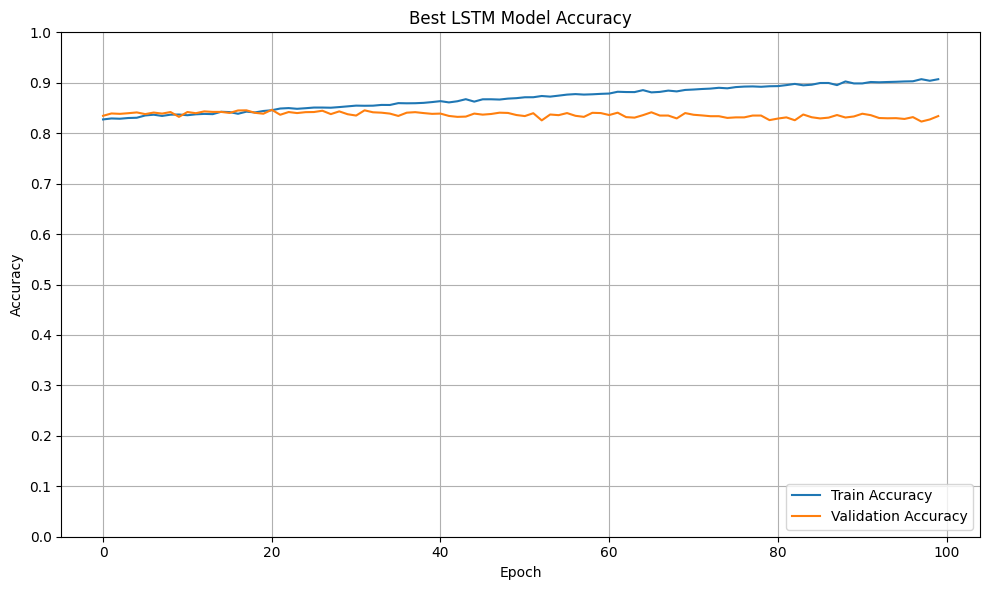

In [ ]:
file_dir = base_save_dir

# Plot training & validation accuracy values
plt.figure(figsize=(10, 6))
plt.plot(history_lstm.history['accuracy'], label='Train Accuracy')
plt.plot(history_lstm.history['val_accuracy'], label='Validation Accuracy')
plt.title('Best LSTM Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([i / 10 for i in range(11)])
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()

# Save the plot to Google Drive
accuracy_plot_path_lstm = os.path.join(file_dir, 'lstm_accuracy_plot_w.png')
plt.savefig(accuracy_plot_path_lstm)
print(f"Best LSTM Model Accuracy plot saved to: {accuracy_plot_path_lstm}")
plt.show()

Best LSTM Model Loss plot saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\lstm_loss_plot_w.png


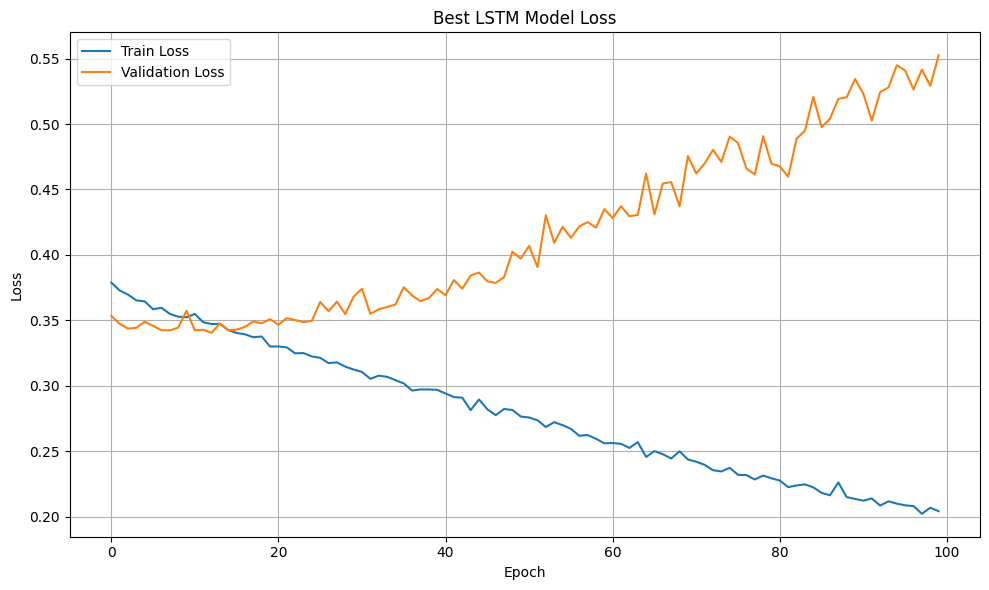

In [ ]:
file_dir = base_save_dir

# Plot training & validation loss values
plt.figure(figsize=(10, 6))
plt.plot(history_lstm.history['loss'], label='Train Loss')
plt.plot(history_lstm.history['val_loss'], label='Validation Loss')
plt.title('Best LSTM Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(loc='upper left')
plt.grid(True)
plt.tight_layout()

# Save the plot to Google Drive
loss_plot_path_lstm = os.path.join(file_dir, 'lstm_loss_plot_w.png')
plt.savefig(loss_plot_path_lstm)
print(f"Best LSTM Model Loss plot saved to: {loss_plot_path_lstm}")
plt.show()

In [ ]:
y_pred_probs_train_best_lstm = best_lstm_model.predict(X_train_lstm)
y_predict_best_lstm_train = np.argmax(y_pred_probs_train_best_lstm, axis=1)

cm_best_lstm_train = confusion_matrix(y_train, y_predict_best_lstm_train)
print("Confusion Matrix for Train Data (Best LSTM Model):")
print(cm_best_lstm_train)

564/564 ━━━━━━━━━━━━━━━━━━━━ 1s 933us/step
Confusion Matrix for Train Data (Best LSTM Model):
[[5845    9  507]
 [  19 5274   13]
 [ 560    2 5816]]


Best LSTM Training Confusion Matrix plot saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\best_lstm_train_confusion_matrix_w.png


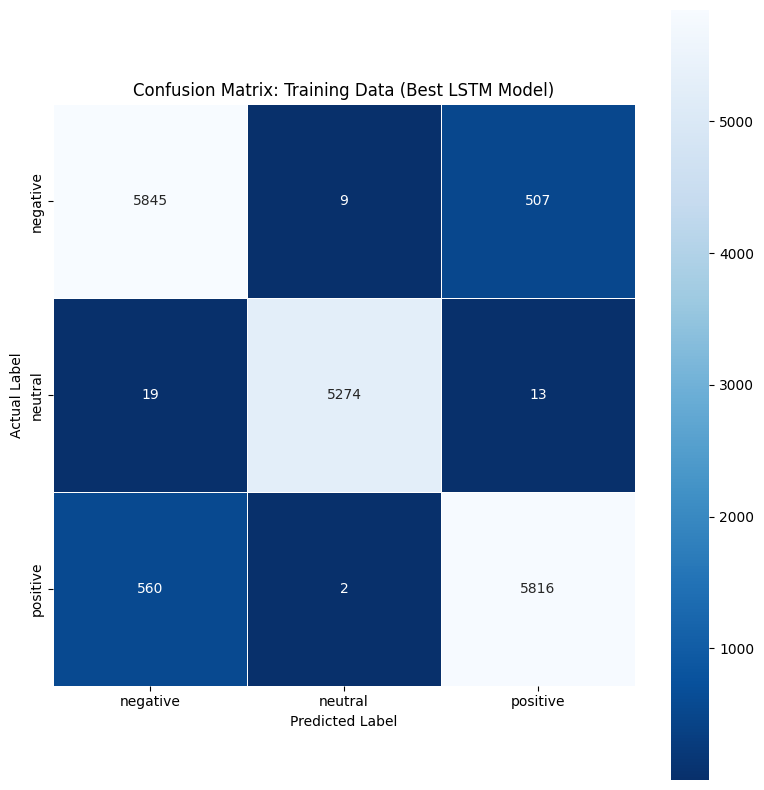

In [ ]:
file_dir = base_save_dir

plt.figure(figsize = (8,8))
sns.heatmap(cm_best_lstm_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix: Training Data (Best LSTM Model)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Save the plot to Google Drive
train_cm_plot_path_best_lstm = os.path.join(file_dir, 'best_lstm_train_confusion_matrix_w.png')
plt.savefig(train_cm_plot_path_best_lstm)
print(f"Best LSTM Training Confusion Matrix plot saved to: {train_cm_plot_path_best_lstm}")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report_best_lstm_train = classification_report(y_train, y_predict_best_lstm_train, target_names=le.classes_)
print("Best LSTM Train Report:\n", report_best_lstm_train)

Best LSTM Train Report:
               precision    recall  f1-score   support

    negative       0.91      0.92      0.91      6361
     neutral       1.00      0.99      1.00      5306
    positive       0.92      0.91      0.91      6378

    accuracy                           0.94     18045
   macro avg       0.94      0.94      0.94     18045
weighted avg       0.94      0.94      0.94     18045

Best LSTM Training Classification Report saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\best_lstm_train_classification_report_w.txt


In [ ]:
y_pred_probs_test_best_lstm = best_lstm_model.predict(X_test_lstm)
y_predict_best_lstm_test = np.argmax(y_pred_probs_test_best_lstm, axis=1)


cm_best_lstm_test = confusion_matrix(y_test, y_predict_best_lstm_test)
print("Confusion Matrix for Test Data (Best LSTM Model):")
print(cm_best_lstm_test)

121/121 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Confusion Matrix for Test Data (Best LSTM Model):
[[1049   16  299]
 [  33 1094   10]
 [ 332    9 1025]]


Best LSTM Test Confusion Matrix plot saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\best_lstm_test_confusion_matrix_w.png


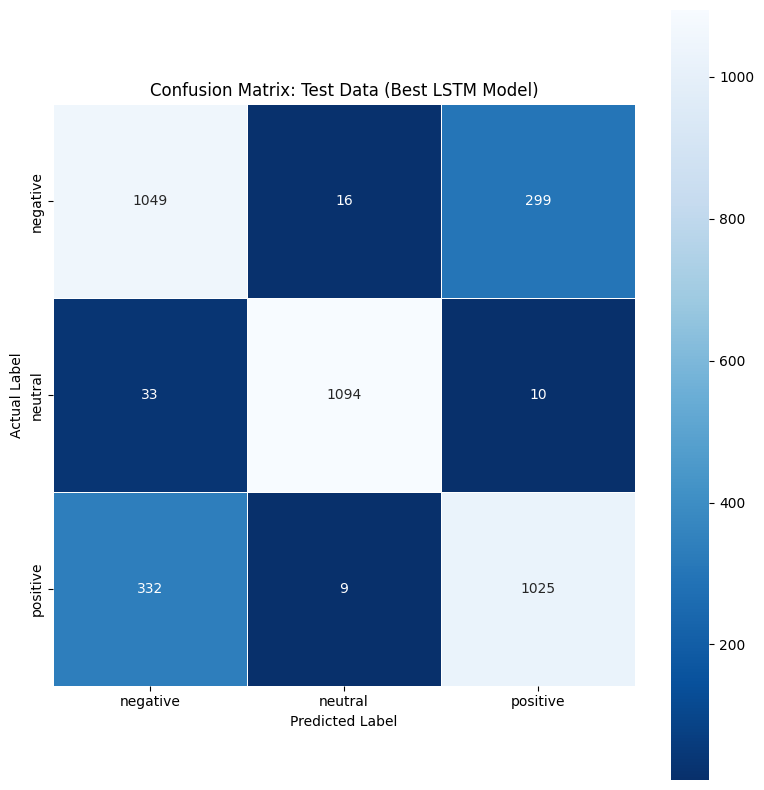

In [ ]:
file_dir = base_save_dir

plt.figure(figsize = (8,8))
sns.heatmap(cm_best_lstm_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix: Test Data (Best LSTM Model)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Save the plot to Google Drive
test_cm_plot_path_best_lstm = os.path.join(file_dir, 'best_lstm_test_confusion_matrix_w.png')
plt.savefig(test_cm_plot_path_best_lstm)
print(f"Best LSTM Test Confusion Matrix plot saved to: {test_cm_plot_path_best_lstm}")
plt.show()

In [ ]:
report_best_lstm_test = classification_report(y_test, y_predict_best_lstm_test, target_names=le.classes_)
print("Best LSTM Test Report:\n", report_best_lstm_test)

Best LSTM Test Report:
               precision    recall  f1-score   support

    negative       0.74      0.77      0.76      1364
     neutral       0.98      0.96      0.97      1137
    positive       0.77      0.75      0.76      1366

    accuracy                           0.82      3867
   macro avg       0.83      0.83      0.83      3867
weighted avg       0.82      0.82      0.82      3867

Best LSTM Test Classification Report saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\best_lstm_test_classification_report_w.txt


Best LSTM Model ROC curve plot saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\best_lstm_roc_curve_w.png


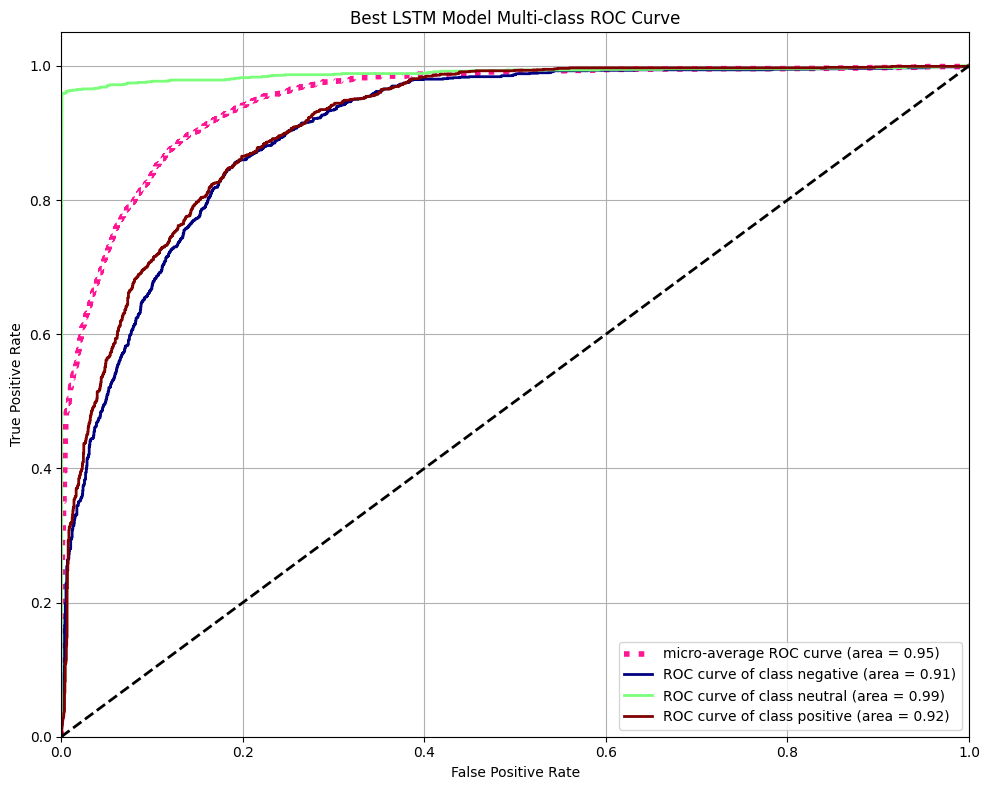

In [ ]:
file_dir = base_save_dir

# Get the number of classes
n_classes = len(le.classes_)

# Convert y_test to one-hot encoding
y_test_one_hot = to_categorical(y_test, num_classes=n_classes)

# Compute ROC curve and ROC area for each class
fpr_best_lstm = dict()
tpr_best_lstm = dict()
roc_auc_best_lstm = dict()
for i in range(n_classes):
    fpr_best_lstm[i], tpr_best_lstm[i], _ = roc_curve(y_test_one_hot[:, i], y_pred_probs_test_best_lstm[:, i])
    roc_auc_best_lstm[i] = auc(fpr_best_lstm[i], tpr_best_lstm[i])

# Compute micro-average ROC curve and ROC area
fpr_micro_best_lstm, tpr_micro_best_lstm, _ = roc_curve(y_test_one_hot.ravel(), y_pred_probs_test_best_lstm.ravel())
roc_auc_micro_best_lstm = auc(fpr_micro_best_lstm, tpr_micro_best_lstm)

# Plot all ROC curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_micro_best_lstm, tpr_micro_best_lstm,
         label='micro-average ROC curve (area = {0:0.2f})'
               ''.format(roc_auc_micro_best_lstm),
         color='deeppink', linestyle=':', linewidth=4)

colors = plt.cm.get_cmap('jet', n_classes)
for i, color in zip(range(n_classes), colors(np.linspace(0, 1, n_classes))):
    plt.plot(fpr_best_lstm[i], tpr_best_lstm[i], color=color, lw=2,
             label='ROC curve of class {0} (area = {1:0.2f})'
                   ''.format(le.classes_[i], roc_auc_best_lstm[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Best LSTM Model Multi-class ROC Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()

# Save the plot
roc_plot_path_best_lstm = os.path.join(file_dir, 'best_lstm_roc_curve_w.png')
plt.savefig(roc_plot_path_best_lstm)
print(f"Best LSTM Model ROC curve plot saved to: {roc_plot_path_best_lstm}")
plt.show()

**GRU**

In [ ]:
X_train_gru = X_train.reshape(X_train.shape[0], 1, X_train.shape[1])
X_test_gru = X_test.reshape(X_test.shape[0], 1, X_test.shape[1])

print(f'Reshaped X_train_gru: {X_train_gru.shape}')
print(f'Reshaped X_test_gru: {X_test_gru.shape}')

Reshaped X_train_gru: (18045, 1, 100)
Reshaped X_test_gru: (3867, 1, 100)


In [ ]:
model_gru = Sequential()

model_gru.add(GRU(units=256, input_shape=(1, X_train.shape[1])))
model_gru.add(BatchNormalization())
model_gru.add(Dropout(0.5))

model_gru.add(Dense(100, activation='elu'))
model_gru.add(BatchNormalization())
model_gru.add(Dropout(0.3))

model_gru.add(Dense(50, activation = 'elu'))
model_gru.add(Dropout(0.3))

# Output layer for multi-class classification (5 classes)
# `le` (LabelEncoder) was defined in a previous cell (s3-code)
model_gru.add(Dense(len(le.classes_), activation='softmax'))

In [ ]:
model_gru.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_gru.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru (GRU)                            │ (None, 256)                 │         274,944 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 100)                 │          25,700 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 100)                 │             400 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 50)                  │           5,050 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 50)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 3)                   │             153 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 307,271 (1.17 MB)

 Trainable params: 306,559 (1.17 MB)

 Non-trainable params: 712 (2.78 KB)

In [ ]:
history_gru = model_gru.fit(X_train_gru, y_train, epochs= 100, batch_size= 32, validation_data=(X_val_gru, y_val))

Epoch 1/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8248 - loss: 0.3806 - val_accuracy: 0.8423 - val_loss: 0.3492
Epoch 2/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8253 - loss: 0.3756 - val_accuracy: 0.8389 - val_loss: 0.3515
Epoch 3/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8284 - loss: 0.3765 - val_accuracy: 0.8394 - val_loss: 0.3527
Epoch 4/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8308 - loss: 0.3693 - val_accuracy: 0.8379 - val_loss: 0.3449
Epoch 5/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8288 - loss: 0.3739 - val_accuracy: 0.8353 - val_loss: 0.3464
Epoch 6/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8287 - loss: 0.3715 - val_accuracy: 0.8340 - val_loss: 0.3677
Epoch 7/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8342 - loss: 0.3627 - val_accuracy: 0.8410 - val_loss: 0.3483
Epoch 8/100
564/564 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8330 - loss: 0.3659 - val_accu

In [ ]:
loss, accuracy = best_gru_model.evaluate(X_test_gru, y_test)
print(f'Test Loss: {loss:.4f}')
print(f'Test Accuracy: {accuracy:.4f}')

121/121 ━━━━━━━━━━━━━━━━━━━━ 0s 967us/step - accuracy: 0.8231 - loss: 0.4497
Test Loss: 0.4497
Test Accuracy: 0.8231


GRU Accuracy plot saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\gru_accuracy_plot_w.png


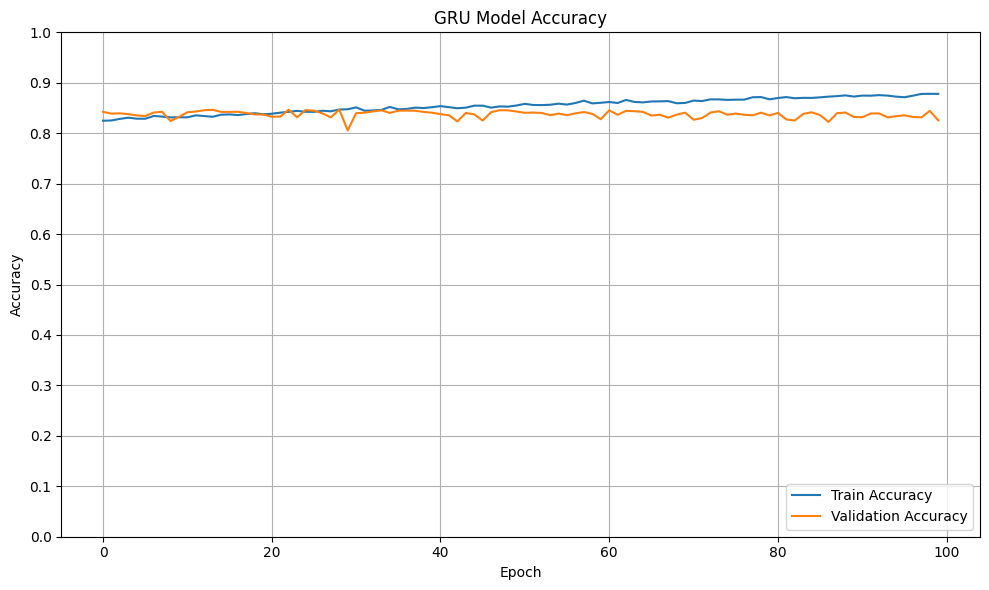

In [ ]:
file_dir = base_save_dir

# Plot training & validation accuracy values
plt.figure(figsize=(10, 6))
plt.plot(history_gru.history['accuracy'], label='Train Accuracy')
plt.plot(history_gru.history['val_accuracy'], label='Validation Accuracy')
plt.title('GRU Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([i / 10 for i in range(11)])
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()

# Save the plot to Google Drive
accuracy_plot_path_gru = os.path.join(file_dir, 'gru_accuracy_plot_w.png')
plt.savefig(accuracy_plot_path_gru)
print(f"GRU Accuracy plot saved to: {accuracy_plot_path_gru}")
plt.show()

GRU Loss plot saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\gru_loss_plot_w.png


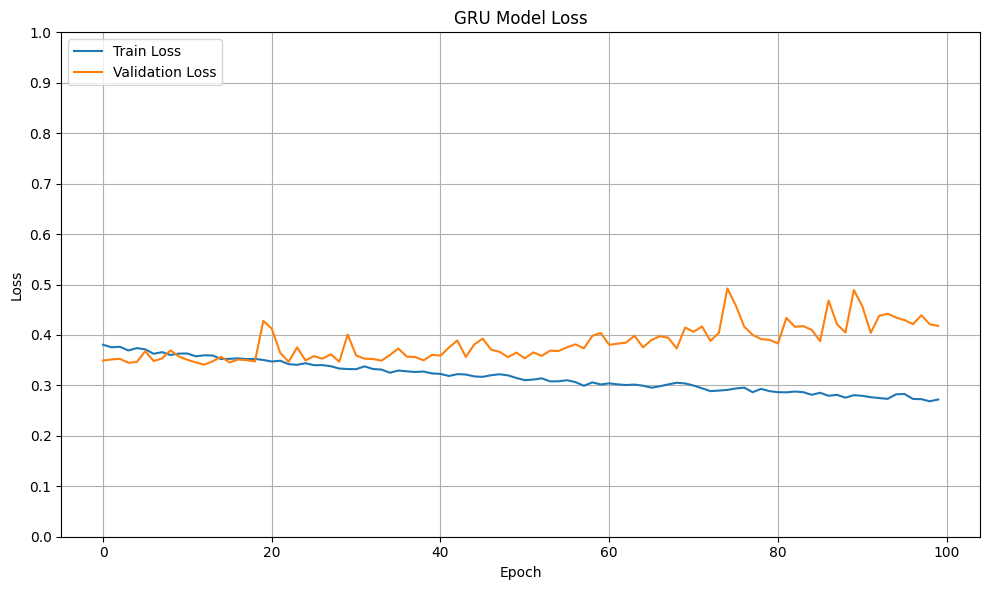

In [ ]:
file_dir = base_save_dir

# Plot training & validation loss values
plt.figure(figsize=(10, 6))
plt.plot(history_gru.history['loss'], label='Train Loss')
plt.plot(history_gru.history['val_loss'], label='Validation Loss')
plt.title('GRU Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.yticks([i / 10 for i in range(11)])
plt.legend(loc='upper left')
plt.grid(True)
plt.tight_layout()

# Save the plot to Google Drive
loss_plot_path_gru = os.path.join(file_dir, 'gru_loss_plot_w.png')
plt.savefig(loss_plot_path_gru)
print(f"GRU Loss plot saved to: {loss_plot_path_gru}")
plt.show()

In [ ]:
y_pred_probs_train_gru = best_gru_model.predict(X_train_gru)
y_predict_gru_train = np.argmax(y_pred_probs_train_gru, axis=1)

# Compute confusion matrix
cm_gru_train = confusion_matrix(y_train, y_predict_gru_train)
print("Confusion Matrix for Train Data (GRU):")
print(cm_gru_train)

564/564 ━━━━━━━━━━━━━━━━━━━━ 0s 819us/step
Confusion Matrix for Train Data (GRU):
[[5976    2  383]
 [ 120 5160   26]
 [1304    4 5070]]


GRU Training Confusion Matrix plot saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\gru_train_confusion_matrix_w.png


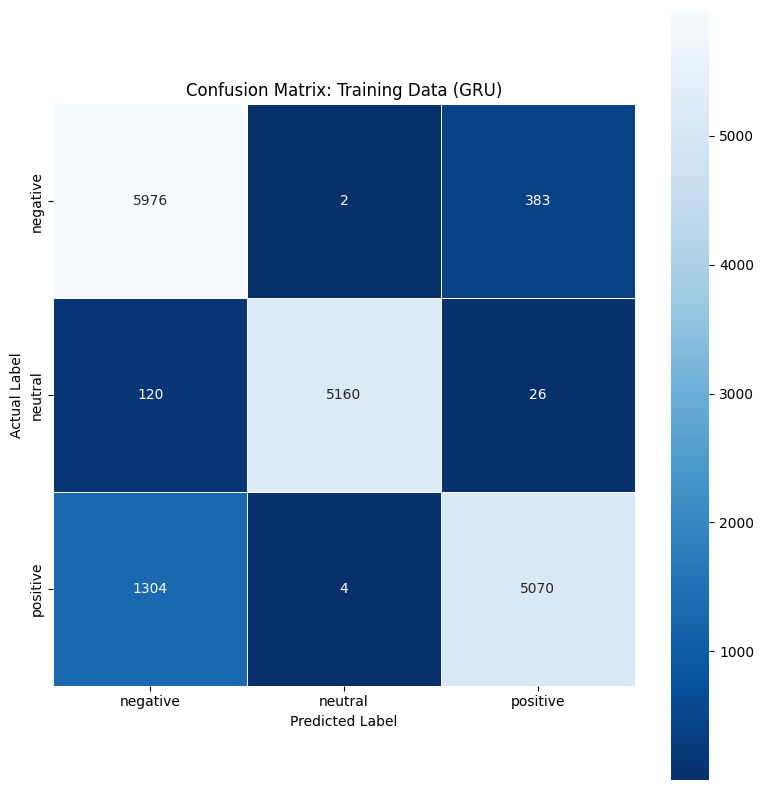

In [ ]:
file_dir = base_save_dir

plt.figure(figsize = (8,8))
sns.heatmap(cm_gru_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix: Training Data (GRU)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Save the plot to Google Drive
train_cm_plot_path_gru = os.path.join(file_dir, 'gru_train_confusion_matrix_w.png')
plt.savefig(train_cm_plot_path_gru)
print(f"GRU Training Confusion Matrix plot saved to: {train_cm_plot_path_gru}")
plt.show()

In [ ]:
report_gru_train = classification_report(y_train, y_predict_gru_train, target_names=le.classes_)
print("GRU Train Report:\n", report_gru_train)

# Save the report to Google Drive
import os
file_dir = base_save_dir # Use base_save_dir directly for consistency
train_report_path_gru = os.path.join(file_dir, 'gru_train_classification_report_w.txt')
with open(train_report_path_gru, 'w') as f:
    f.write("GRU Train Report:\n")
    f.write(report_gru_train)
print(f"GRU Training Classification Report saved to: {train_report_path_gru}")

GRU Train Report:
               precision    recall  f1-score   support

    negative       0.81      0.94      0.87      6361
     neutral       1.00      0.97      0.99      5306
    positive       0.93      0.79      0.86      6378

    accuracy                           0.90     18045
   macro avg       0.91      0.90      0.90     18045
weighted avg       0.91      0.90      0.90     18045

GRU Training Classification Report saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\gru_train_classification_report_w.txt


In [ ]:
y_pred_probs_test_gru = best_gru_model.predict(X_test_gru)
y_predict_gru_test = np.argmax(y_pred_probs_test_gru, axis=1)

# Compute confusion matrix
cm_gru_test = confusion_matrix(y_test, y_predict_gru_test)
print("Confusion Matrix for Test Data (GRU):")
print(cm_gru_test)

121/121 ━━━━━━━━━━━━━━━━━━━━ 0s 892us/step
Confusion Matrix for Test Data (GRU):
[[1161    3  200]
 [  37 1090   10]
 [ 431    3  932]]


GRU Test Confusion Matrix plot saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\gru_test_confusion_matrix_w.png


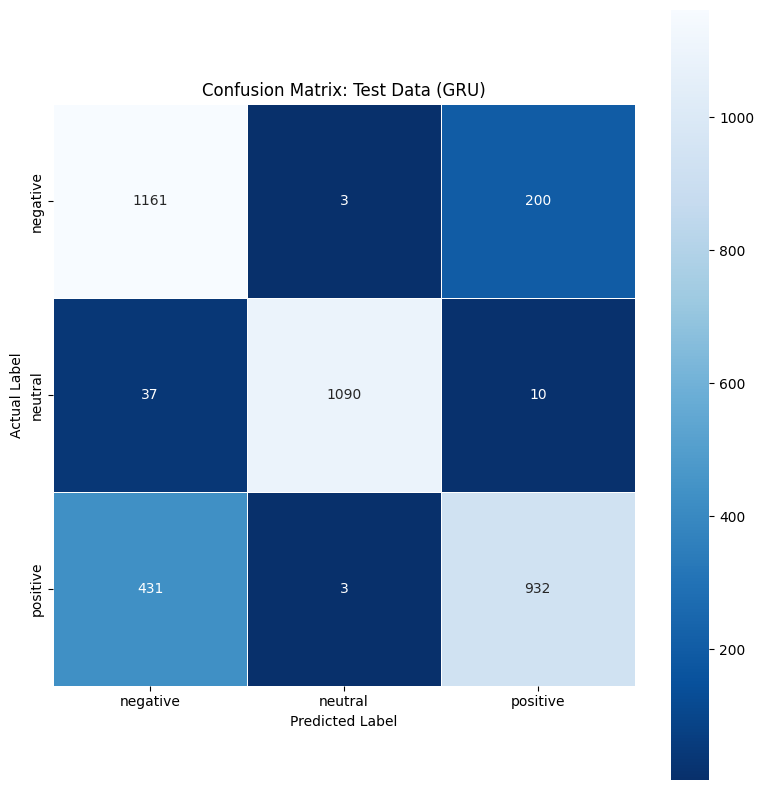

In [ ]:
plt.figure(figsize = (8,8))
sns.heatmap(cm_gru_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix: Test Data (GRU)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Save the plot to Google Drive
test_cm_plot_path_gru = os.path.join(file_dir, 'gru_test_confusion_matrix_w.png')
plt.savefig(test_cm_plot_path_gru)
print(f"GRU Test Confusion Matrix plot saved to: {test_cm_plot_path_gru}")
plt.show()

In [ ]:
report_gru_test = classification_report(y_test, y_predict_gru_test, target_names=le.classes_)
print("GRU Test Report:\n", report_gru_test)

# Save the report to Google Drive
import os
file_dir = base_save_dir # Use base_save_dir instead of undefined x_word2vec_path
test_report_path_gru = os.path.join(file_dir, 'gru_test_classification_report_w.txt')
with open(test_report_path_gru, 'w') as f:
    f.write("GRU Test Report:\n")
    f.write(report_gru_test)
print(f"GRU Test Classification Report saved to: {test_report_path_gru}")

GRU Test Report:
               precision    recall  f1-score   support

    negative       0.71      0.85      0.78      1364
     neutral       0.99      0.96      0.98      1137
    positive       0.82      0.68      0.74      1366

    accuracy                           0.82      3867
   macro avg       0.84      0.83      0.83      3867
weighted avg       0.83      0.82      0.82      3867

GRU Test Classification Report saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\gru_test_classification_report_w.txt


GRU ROC curve plot saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\gru_roc_curve_w.png


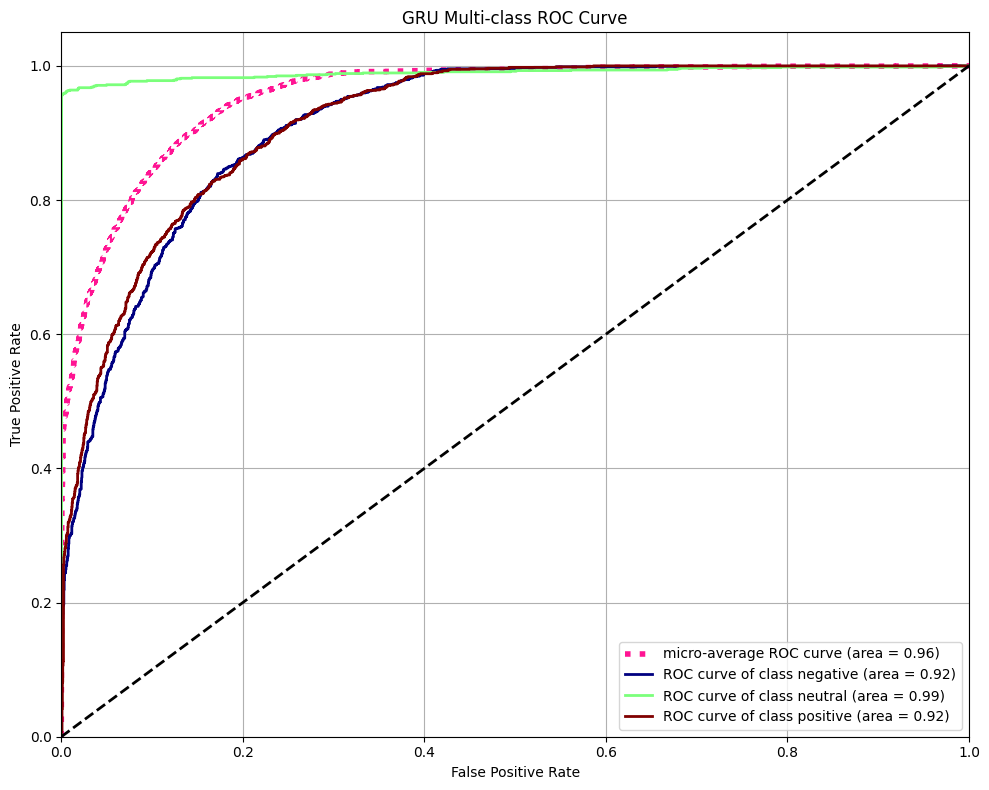

In [ ]:
# Convert y_test to one-hot encoding
y_test_one_hot = to_categorical(y_test, num_classes=n_classes)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_one_hot[:, i], y_pred_probs_test_gru[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and ROC area
fpr_micro, tpr_micro, _ = roc_curve(y_test_one_hot.ravel(), y_pred_probs_test_gru.ravel())
roc_auc_micro = auc(fpr_micro, tpr_micro)

# Plot all ROC curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_micro, tpr_micro,
         label='micro-average ROC curve (area = {0:0.2f})'
               ''.format(roc_auc_micro),
         color='deeppink', linestyle=':', linewidth=4)

colors = plt.cm.get_cmap('jet', n_classes)
for i, color in zip(range(n_classes), colors(np.linspace(0, 1, n_classes))):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='ROC curve of class {0} (area = {1:0.2f})'
                   ''.format(le.classes_[i], roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('GRU Multi-class ROC Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()

# Save the plot
roc_plot_path_gru = os.path.join(file_dir, 'gru_roc_curve_w.png')
plt.savefig(roc_plot_path_gru)
print(f"GRU ROC curve plot saved to: {roc_plot_path_gru}")
plt.show()